# Portfolio aggregation: coupons, payments and risk

We combine six USD positions: two fixed-rate deposits, three receive-fixed
swaps and one short swap. The example asks which payments can be compressed
into equivalent coupons while retaining the index used to fix each floating
payment. We also reconcile PV, cash payments and every sensitivity against
independently evaluated positions.

The market is an **illustrative 24 February 2026** snapshot. Every USD payment
is discounted on SOFR. SOFR and TermSOFR3m have distinct projection curves.
All rates and spreads are annual decimals: `0.04` means 4%, and `0.001`
means 10 bp. Amounts are signed receipts/payments in USD.

Run all cells in order with a binding built from this checkout and the
[example dependencies](../README.md#install-and-run). This notebook defines
all market inputs inline. The [matching Excel workbook](../../../excel/examples/workbooks/portfolio_aggregation_example.xlsx)
uses the same book, dates and curves.


In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")


## 1. Define the positions

Edit the notionals, fixed rates or floating spreads below. Instruments hold
contractual terms; each `Trade` adds direction and execution date.
`LongReceive` deposits advance principal, then receive interest and redemption.
`LongReceive` swaps receive fixed and pay floating; `PayShort` reverses that.

Both deposit coupons have the same period. The SOFR and TermSOFR3m swaps
deliberately share payment dates so we can verify that their floating
coupons remain distinguishable. Repeating a trade in a `Portfolio` counts
it as another position.


In [2]:
VALUATION_DATE = "2026-02-24"
START = "2026-03-02"
DEPOSIT_MATURITY = "2026-09-02"
SWAP_MATURITY = "2028-03-02"
REQUESTS = ["Value", "Sensitivities", "Cashflows"]
POSITIONS = [
    # name, instrument, principal, fixed rate, floating spread, index, side
    ("Deposit A", "Deposit", 100_000.0, 0.04, 0.0, "SOFR", "LongReceive"),
    ("Deposit B", "Deposit", 300_000.0, 0.06, 0.0, "SOFR", "LongReceive"),
    ("SOFR A", "Swap", 100_000.0, 0.04, 0.001, "SOFR", "LongReceive"),
    ("SOFR B", "Swap", 300_000.0, 0.06, 0.003, "SOFR", "LongReceive"),
    ("Term SOFR", "Swap", 200_000.0, 0.055, 0.002, "TermSOFR3m", "LongReceive"),
    ("Short SOFR", "Swap", 50_000.0, 0.04, 0.001, "SOFR", "PayShort"),
]

positions = pd.DataFrame(POSITIONS, columns=[
    'position', 'instrument', 'notional', 'rate', 'spread', 'index', 'side',
])
positions


,position,instrument,notional,rate,spread,index,side
0,Deposit A,Deposit,"100,000.000000",0.040000,0.000000,SOFR,LongReceive
1,Deposit B,Deposit,"300,000.000000",0.060000,0.000000,SOFR,LongReceive
2,SOFR A,Swap,"100,000.000000",0.040000,0.001000,SOFR,LongReceive
3,SOFR B,Swap,"300,000.000000",0.060000,0.003000,SOFR,LongReceive
4,Term SOFR,Swap,"200,000.000000",0.055000,0.002000,TermSOFR3m,LongReceive
5,Short SOFR,Swap,"50,000.000000",0.040000,0.001000,SOFR,PayShort


## 2. Build two projection curves

The explicit continuous zero rates use Actual360 and linear interpolation.
SOFR is flat at 3%; TermSOFR3m is flat at 3.5%. Both are USD indices, so this
study needs no FX conversion. The SOFR CSA policy discounts every position's
USD payments, including the swaps projected from TermSOFR3m.

All accrual starts follow the valuation date; historical fixings are not
needed. Changing a rate here and rerunning from a fresh kernel gives a
different market, without changing contractual coupon spreads.


In [3]:
curves = [
    qs.CurveConfiguration(
        market_index=index,
        quotes=[f"ZeroRate_USD_{index}_{tenor}" for tenor in ["0D", "1Y", "3Y"]],
        day_counter="Actual360", interpolator="Linear", enable_extrapolation=True,
    )
    for index, rate in [("SOFR", 0.03), ("TermSOFR3m", 0.035)]
]
context = qs.PricingContext(
    quotes=qs.QuoteStore.from_dict({"reference_date": VALUATION_DATE, "quotes": [
        {"identifier": f"ZeroRate_USD_{index}_{tenor}", "mid": rate}
        for index, rate in [("SOFR", 0.03), ("TermSOFR3m", 0.035)]
        for tenor in ["0D", "1Y", "3Y"]
    ]}),
    curves=curves,
    csa_policy=qs.SingleCurveCSADiscountPolicy("USD", "SOFR"),
)

pd.DataFrame({'pillar': ['0D', '1Y', '3Y'], 'SOFR': [0.03] * 3, 'TermSOFR3m': [0.035] * 3})


,pillar,SOFR,TermSOFR3m
0,0D,0.030000,0.035000
1,1Y,0.030000,0.035000
2,3Y,0.030000,0.035000


## 3. Create instruments, trades and the portfolio

Deposit maturity is six months after the common start. Swaps have two annual
fixed and floating periods. Simple/Annual fixed-rate conventions and
Actual360 accrual are explicit in both bindings.


In [4]:
trades = []
for name, kind, notional, rate, spread, index, side in POSITIONS:
    common = dict(
        identifier=name, start_date=START, notional=notional, currency="USD",
        day_counter="Actual360", compounding="Simple", rate_frequency="Annual",
    )
    if kind == "Deposit":
        instrument = qs.FixedRateDeposit(
            **common, maturity_date=DEPOSIT_MATURITY, rate=rate, discount_index=index,
        )
    else:
        instrument = qs.Swap(
            **common, maturity_date=SWAP_MATURITY, fixed_rate=rate,
            market_index=index, spread=spread,
            fixed_leg_frequency="Annual", floating_leg_frequency="Annual",
        )
    trades.append(qs.Trade(instrument, VALUATION_DATE, side))
book = qs.Portfolio("PORTFOLIO", trades)
book


Portfolio(identifier="PORTFOLIO", trades=6)

## 4. Evaluate, then build an independent reference

`context.evaluate(book, REQUESTS)` returns normal `EvaluationResults`. It evaluates each
original trade and immediately combines completed numeric results; built-in
pricers reuse the per-trade AD tape. Coupon compression does not replace the
original trades for valuation or differentiation.

The context supplies its base currency and FX conversion automatically;
all members here produce USD PVs and derivatives. The small reference loop below
is only a reconciliation: we sum numerical values, risk labels and payments
from separate position evaluations. The active context closes before we
inspect the saved numeric results in later cells.


In [5]:
individual_values = []
expected_risk = defaultdict(float)
expected_payments = defaultdict(float)
original_rows = 0

with context:
    result = context.evaluate(book, REQUESTS)
    for spec, trade in zip(POSITIONS, trades):
        single = context.evaluate(trade, REQUESTS)
        individual_values.append((spec[0], single.price))
        for factor, exposure in single.raw_sensitivities:
            expected_risk[factor] += exposure
        for row in single.cashflows.itertuples(index=False):
            expected_payments[row.payment_date, row.currency] += row.amount
            original_rows += 1

position_values = pd.DataFrame(individual_values, columns=["position", "pv_usd"])
display(position_values)
pv_check = pd.DataFrame([{
    "positions": len(book),
    "portfolio_pv_usd": result.price,
    "individual_pv_sum_usd": position_values.pv_usd.sum(),
    "difference_usd": result.price - position_values.pv_usd.sum(),
}])
pv_check


,position,pv_usd
0,Deposit A,491.451989
1,Deposit B,"4,492.849455"
2,SOFR A,"1,655.716292"
3,SOFR B,"15,438.437883"
4,Term SOFR,"6,736.809538"
5,Short SOFR,-827.858146


,positions,portfolio_pv_usd,individual_pv_sum_usd,difference_usd
0,6,"27,987.407011","27,987.407011",0.000000


## 5. Inspect an equivalent fixed coupon

`result.coupons` retains original cashflow types and contractual terms. For
compatible fixed coupons, the equivalent rate is notional weighted:

$$N_{eq}=\sum_i N_i,\qquad r_{eq}=\frac{\sum_i N_i r_i}{\sum_i N_i}.$$

With the default inputs, deposits of 100,000 at 4% and 300,000 at 6%
become **400,000 at 5.5%**. Payment and accrual dates, currency, day count
and rate conventions must match. Opposing directions stay separate, which
avoids an undefined weighted quote at zero net notional. The detailed table
also retains capital rows, whose coupon metadata is blank.


In [6]:
coupons = result.coupons
deposits = coupons[
    (coupons.type == "FixedRateCoupon") & (coupons.accrual_end == DEPOSIT_MATURITY)
]
deposit_specs = [spec for spec in POSITIONS if spec[1] == "Deposit"]
deposit_notional = sum(spec[2] for spec in deposit_specs)
deposit_rate = sum(spec[2] * spec[3] for spec in deposit_specs) / deposit_notional
deposits[["type", "accrual_start", "accrual_end", "payment_date", "currency",
          "notional", "rate", "amount", "day_counter", "rate_definition"]]


,type,accrual_start,accrual_end,payment_date,currency,notional,rate,amount,day_counter,rate_definition
4,FixedRateCoupon,2026-03-02,2026-09-02,2026-09-02,USD,"400,000.000000",0.055000,"11,244.444444",Actual360,"RateDefinition { day_counter: Actual360, compo..."


## 6. Preserve floating indices and weighted spreads

For compatible linear floating coupons, use the same weighting for spread:

$$s_{eq}=\frac{\sum_i N_i s_i}{\sum_i N_i}.$$

The two receive-fixed SOFR swaps pay floating on **-400,000 at a 25 bp
spread**. TermSOFR3m remains separate at -200,000 and 20 bp, even on the
same dates. The short SOFR swap receives floating on +50,000 at 10 bp.
`market_index` is the contractual index; `fixing_index` also reflects a
leg-level forecasting override when one is present.

Different observation rules, day counts or nonlinear payoffs stay distinct.
Daily-compounded spreads are not averaged together. Cashflows without
sufficient contractual metadata remain individual rows.


In [7]:
floating = coupons[coupons.type == "FloatingRateCoupon"]
sofr_paid = floating[(floating.fixing_index == "SOFR") & (floating.notional < 0)]
sofr_specs = [
    spec for spec in POSITIONS
    if spec[1] == "Swap" and spec[5] == "SOFR" and spec[6] == "LongReceive"
]
sofr_notional = sum(spec[2] for spec in sofr_specs)
sofr_spread = sum(spec[2] * spec[4] for spec in sofr_specs) / sofr_notional
floating[["payment_date", "accrual_start", "accrual_end", "market_index",
          "fixing_index", "notional", "fixing", "spread", "amount"]]


,payment_date,accrual_start,accrual_end,market_index,fixing_index,notional,fixing,spread,amount
8,2027-03-02,2026-03-02,2027-03-02,SOFR,SOFR,"-400,000.000000",0.030461,0.002500,"-13,367.480677"
9,2027-03-02,2026-03-02,2027-03-02,TermSOFR3m,TermSOFR3m,"-200,000.000000",0.035628,0.002000,"-7,630.207041"
10,2027-03-02,2026-03-02,2027-03-02,SOFR,SOFR,"50,000.000000",0.030461,0.001000,"1,594.893418"
13,2028-03-02,2027-03-02,2028-03-02,SOFR,SOFR,"-400,000.000000",0.030462,0.002500,"-13,404.622686"
14,2028-03-02,2027-03-02,2028-03-02,TermSOFR3m,TermSOFR3m,"-200,000.000000",0.035630,0.002000,"-7,651.465973"
15,2028-03-02,2027-03-02,2028-03-02,SOFR,SOFR,"50,000.000000",0.030462,0.001000,"1,599.327836"


In [8]:
compression = pd.DataFrame([{
    "individual_cashflow_rows": original_rows,
    "aggregated_cashflow_rows": len(coupons),
    "rows_combined": original_rows - len(coupons),
}])
compression


,individual_cashflow_rows,aggregated_cashflow_rows,rows_combined
0,38,20,18


## 7. Separate interest from principal payments

`cashflow_summary` is a separate view grouped by payment date and original
currency. Interest includes fixed and floating coupons. Capital includes
redemptions less advances; unclassified types appear in Other. Swap
principal exchanges offset across the two legs in this book, leaving the
deposit's advance and redemption visible.

These are **signed, undiscounted cash payments**, retained on their payment
dates. They do not allocate interest across accrual periods and are not yet
an accrual NII forecast. Every payment-date total is checked against the
independently evaluated positions.


In [9]:
summary = result.cashflow_summary
summary


,payment_date,currency,interest,capital,other,total
0,2026-03-02,USD,0.000000,"-400,000.000000",0.000000,"-400,000.000000"
1,2026-09-02,USD,"11,244.444444","400,000.000000",0.000000,"411,244.444444"
2,2027-03-02,USD,"12,027.761255",0.000000,0.000000,"12,027.761255"
3,2028-03-02,USD,"12,059.905844",0.000000,0.000000,"12,059.905844"


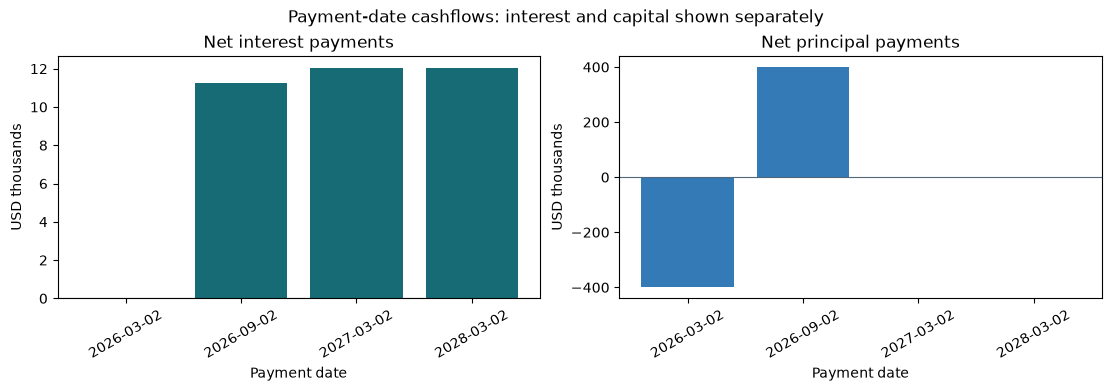

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for axis, field, label, color in zip(
    axes, ["interest", "capital"], ["Net interest payments", "Net principal payments"],
    ["#176B75", "#337AB7"],
):
    axis.bar(summary.payment_date, summary[field] / 1_000, color=color)
    axis.axhline(0, color="#526779", linewidth=0.8)
    axis.set(title=label, xlabel="Payment date", ylabel="USD thousands")
    axis.tick_params(axis="x", labelrotation=30)
fig.suptitle("Payment-date cashflows: interest and capital shown separately")
plt.show()


## 8. Reconcile portfolio sensitivities

The portfolio sums numeric derivatives by each pricer's exact risk-factor
label after differentiation. Both projection curves remain identifiable.
Compare every exposure with the reference sum before interpreting risk.

These inputs are annual decimal zero rates. Multiplying a derivative by
`0.0001` estimates the PV change from increasing that **single pillar by
1 bp**. This unit conversion is specific to these rate inputs; it is not
a universal rule for FX, futures prices or volatility inputs.


In [11]:
actual_risk = dict(result.raw_sensitivities)
risk = result.sensitivities.copy()
risk["individual_sum"] = risk.pillar.map(expected_risk)
risk["difference"] = risk.value - risk.individual_sum
risk["pv_change_for_1bp_usd"] = risk.value * 0.0001
risk


,pillar,value,individual_sum,difference,pv_change_for_1bp_usd
0,ZeroRate_USD_SOFR_0D,"-90,139.933283","-90,139.933283",0.000000,-9.013993
1,ZeroRate_USD_SOFR_1Y,"-486,216.201384","-486,216.201384",0.000000,-48.621620
2,ZeroRate_USD_SOFR_3Y,"-365,537.431674","-365,537.431674",0.000000,-36.553743
3,ZeroRate_USD_TermSOFR3m_0D,"3,293.554194","3,293.554194",0.000000,0.329355
4,ZeroRate_USD_TermSOFR3m_1Y,"-202,047.770828","-202,047.770828",0.000000,-20.204777
5,ZeroRate_USD_TermSOFR3m_3Y,"-203,100.086583","-203,100.086583",0.000000,-20.310009


## 9. Optional CSV exports

Change `EXPORT_CSV` to `True` to write five numeric tables beside the
notebook. The default run only displays results.


In [12]:
tables = {
    "positions": positions,
    "position_values": position_values,
    "coupons": coupons,
    "cashflow_summary": summary,
    "sensitivities": result.sensitivities,
}
EXPORT_CSV = False
output_dir = Path("portfolio_aggregation_outputs")
if EXPORT_CSV:
    output_dir.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_csv(output_dir / f"{name}.csv", index=False)
    print(f"Exported tables to {output_dir}")
print("PV, all sensitivities, payment totals, weighted quotes and index separation checks passed.")


PV, all sensitivities, payment totals, weighted quotes and index separation checks passed.


## Try changing an input

- Increase Deposit B's notional or fixed rate. Check the deposit's equivalent
  principal/rate and its interest payment.
- Change SOFR B's floating spread. Check the weighted paid SOFR spread while
  the short SOFR and TermSOFR3m coupons remain separate.
- Increase the TermSOFR3m zero rates. Its projected payments change while
  its contractual spread stays at 20 bp.

Restart the kernel and run all cells after changing inputs. The assertions
describe this book's structure; removing an index or reversing all positions
requires adapting those book-specific checks. PV and risk still use the
original positions rather than repricing only the compressed coupon rows.
